# 13 · DCRNN: traffic as diffusion on a directed road graph

**Objective.** Rung 3 of the ladder. Train (on Kaggle) and inspect the Diffusion Convolutional Recurrent Neural Network of Li et al. (ICLR 2018), the model that introduced METR-LA as a benchmark.

**Concept.** Congestion spreads along roads. Upstream traffic reaches a sensor a few minutes later; a jam downstream backs up towards it. DCRNN writes this as a **random walk on the directed graph**:

* `S_f = (D_out⁻¹ A)ᵀ`: one step of "what flows in from upstream"
* `S_b = (D_in⁻¹ Aᵀ)ᵀ`: one step of "what backs up from downstream"
* a **diffusion convolution** mixes a sensor's state with `S_f x, S_f² x, S_b x, S_b² x` (K = 2 hops each way), each with its own learned weights

It then replaces every matrix multiply inside a GRU cell with this diffusion convolution (the **DCGRU** cell) and stacks the cells as an encoder–decoder (seq2seq): the encoder reads 12 past steps, the decoder writes 12 future steps one at a time.

| Piece | What it does | Why |
|---|---|---|
| diffusion conv | graph mixing that respects edge direction | traffic on a freeway is not symmetric |
| GRU gates | decide what to keep from the previous step | carry state across time |
| seq2seq decoder | feeds its own last prediction back in | each horizon conditions on the earlier ones |
| teacher forcing (decaying) | early in training, feed the *true* previous value instead | stable start, then learn to live with own errors |

Training ran on a Kaggle T4 (`python -m deep_learning.kaggle.launch push --slug metr-dl-dcrnn --models dcrnn`); this notebook only loads the saved weights and predictions, so it runs in a minute on a laptop.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}")

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from src import preprocessing as pp, visualization as viz, evaluation as ev
from src.graph_utils import load_graph_artifacts
from deep_learning.dl.data import WindowData
from deep_learning.dl import engine
from deep_learning.dl.models import build
from deep_learning.dl.models.dcrnn import random_walk_supports, diffusion_powers

viz.apply_style()
ctx = pp.load_context()
adj = load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids).adjacency
data = WindowData.from_context(ctx, "cpu")
RUN = "dl_dcrnn_s42"
print("adjacency", adj.shape, "| directed edges (no self-loops):", int((adj > 0).sum() - (np.diag(adj) > 0).sum()))

adjacency (207, 207) | directed edges (no self-loops): 1515


## 1 · The two random-walk matrices

`D_out⁻¹ A` is a random walk: each row sums to 1. The model uses its **transpose** (as the original DCRNN code does), so in `S_f` each **column** sums to 1: every sensor sends out its state as a probability distribution over the sensors it flows into, and a sensor fed by many upstream roads gathers more than one unit. Raising the matrix to a power walks further: `S_f²` reaches sensors two edges upstream.

forward : column sums 1.000-1.000 (a distribution) | row sums 0.29-2.10
backward: column sums 1.000-1.000 (a distribution) | row sums 0.40-2.01


,S_f,S_f^2,S_b,S_b^2
mean,8.3,23.3,8.3,23.3
median,8.0,25.0,8.0,25.0
max,18.0,43.0,19.0,44.0


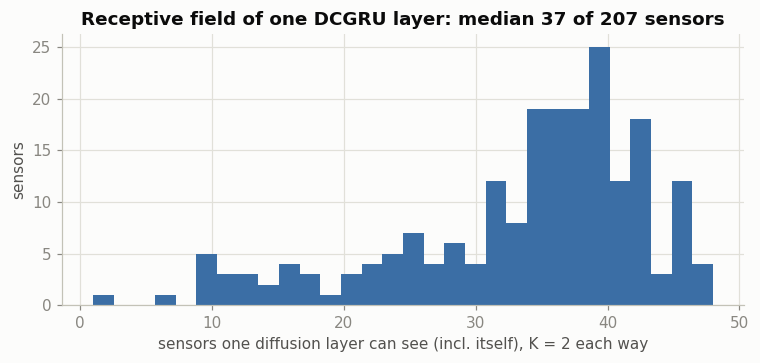

In [3]:
S = random_walk_supports(adj)                  # [2, N, N]
P = diffusion_powers(S, k_hops=2)              # [4, N, N] = S_f, S_f^2, S_b, S_b^2
cols, rows = S.sum(-2), S.sum(-1)
for i, d in enumerate(["forward ", "backward"]):
    print(f"{d}: column sums {cols[i].min():.3f}-{cols[i].max():.3f} (a distribution) | row sums {rows[i].min():.2f}-{rows[i].max():.2f}")
assert torch.allclose(cols, torch.ones_like(cols), atol=1e-5)

reach = pd.DataFrame({name: (P[i] > 0).sum(-1).numpy() for i, name in enumerate(["S_f", "S_f^2", "S_b", "S_b^2"])})
display(reach.describe().loc[["mean", "50%", "max"]].round(1).rename(index={"50%": "median"}))

fig, ax = plt.subplots(figsize=(8, 3.2))
recept = ((P > 0).any(0)).sum(-1).numpy()
ax.hist(recept, bins=30, color="#3b6ea5")
ax.set(xlabel="sensors one diffusion layer can see (incl. itself), K = 2 each way", ylabel="sensors",
       title=f"Receptive field of one DCGRU layer: median {np.median(recept):.0f} of 207 sensors")
plt.show()

**Reading it.** One hop reaches about 8 sensors, two hops about 25, and one layer (both directions) a few dozen of the 207. Two stacked layers and 12 recurrent steps widen that further. This is the opposite design choice to attention (notebook 12), which lets the model *learn* weights over the neighbours but still only over the graph's edges.

## 2 · Load the trained model and check it reproduces the saved predictions

A reproducibility check that can fail: rebuild the architecture, load the Kaggle weights, predict 128 validation windows on the CPU and compare with the prediction file written on the GPU.

In [4]:
model = build("dcrnn", adj)
summary = engine.load_weights(model, config.ARTIFACTS / "models" / f"{RUN}.pt")
model.eval()
print(f"parameters: {engine.count_parameters(model):,} | best epoch {summary['best_epoch']} | "
      f"best val MAE {summary['best_val_mae_mph']:.3f} mph | trained on {summary['device']}")

saved = ev.load_predictions(RUN, "val", clip=False)
idx = slice(0, 128)
with torch.no_grad():
    z = model(data.batch(data.origins["val"][idx]))
mine = data.to_mph(z[:, [h - 1 for h in saved["horizons"]], :])
gap = np.abs(mine - saved["pred"][idx]).max()
print(f"largest difference CPU vs Kaggle GPU: {gap:.4f} mph")
assert gap < 0.05, "weights or data pipeline do not reproduce the saved predictions"

parameters: 380,033 | best epoch 19 | best val MAE 2.799 mph | trained on cuda:0


largest difference CPU vs Kaggle GPU: 0.0002 mph


## 3 · Training curve

The history file has one row per epoch. Watch three things: the train/validation gap (over-fitting), the teacher-forcing ratio (falls linearly to 0 over the first 40 % of `max_epochs`), and the learning rate (halved when validation stalls for 3 epochs).

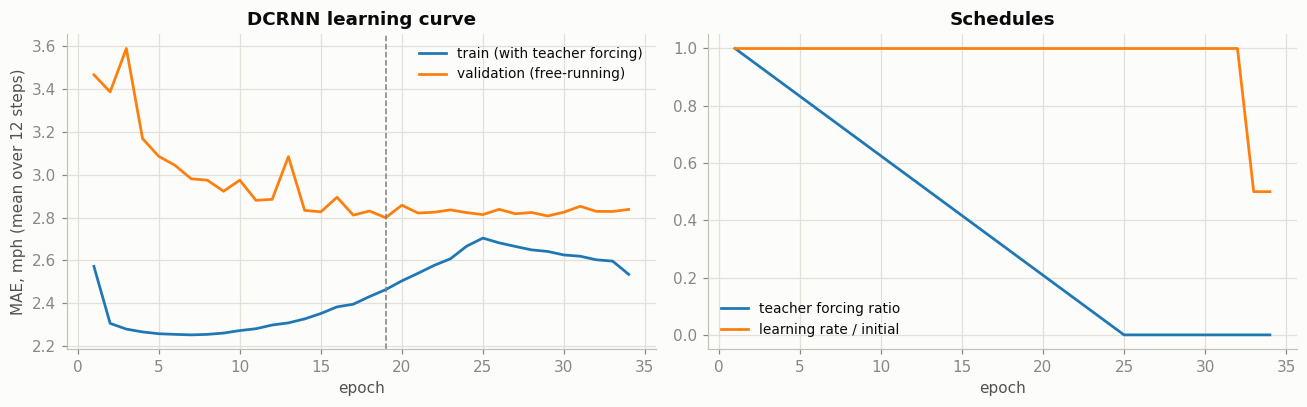

34 epochs, 159 s per epoch on the T4, 1.5 h in total; early stop after 15 epochs without improvement


In [5]:
h = pd.read_csv(config.ARTIFACTS / "metrics" / f"{RUN}_history.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(h.epoch, h.train_mae_mph, label="train (with teacher forcing)")
a1.plot(h.epoch, h.val_mae_mph, label="validation (free-running)")
a1.axvline(summary["best_epoch"], ls="--", c="grey", lw=1)
a1.set(xlabel="epoch", ylabel="MAE, mph (mean over 12 steps)", title="DCRNN learning curve")
a1.legend()
a2.plot(h.epoch, h.teacher_forcing, label="teacher forcing ratio")
a2.plot(h.epoch, h.lr / h.lr.max(), label="learning rate / initial")
a2.set(xlabel="epoch", title="Schedules")
a2.legend()
plt.tight_layout(); plt.show()
print(f"{len(h)} epochs, {h.seconds.mean():.0f} s per epoch on the T4, {h.seconds.sum() / 3600:.1f} h in total; "
      f"early stop after {len(h) - summary['best_epoch']} epochs without improvement")

**Why does the train curve start *below* validation and then cross?** Early on, teacher forcing hands the decoder the true previous speed, which makes training artificially easy. As the ratio falls to 0 the training task becomes the same as the validation task, and the train MAE rises to meet it.

## 4 · Test set: DCRNN against the Phase 1 models

Same windows, same common mask (a point counts only if every model has a finite prediction and the target was observed), predictions clipped to 0–70 mph.

In [6]:
keys = ["persistence", "xgboost", "xgboost_spatial", RUN]
preds, y, ymask, origins, horizons, missing = ev.load_aligned(keys, "test", ctx.speed, ctx.mask)
valid = ev.common_valid_mask(preds, ymask)
t = ev.metrics_by_horizon(preds, y, valid, horizons)
table = t.pivot(index="model", columns="horizon_min", values="MAE").loc[keys].round(3)
table.columns = [f"MAE @ {c} min" for c in table.columns]
display(table)
display(t.pivot(index="model", columns="horizon_min", values="RMSE").loc[keys].round(3).add_prefix("RMSE @ "))

,MAE @ 5 min,MAE @ 15 min,MAE @ 30 min,MAE @ 60 min
model,,,,
persistence,2.816,3.492,4.189,5.347
xgboost,2.310,2.835,3.262,3.685
xgboost_spatial,2.230,2.759,3.182,3.651
dl_dcrnn_s42,2.206,2.666,3.045,3.494


horizon_min,RMSE @ 5,RMSE @ 15,RMSE @ 30,RMSE @ 60
model,,,,
persistence,4.613,6.376,7.985,10.245
xgboost,4.080,5.591,6.639,7.530
xgboost_spatial,3.854,5.306,6.361,7.386
dl_dcrnn_s42,3.776,5.102,6.182,7.338


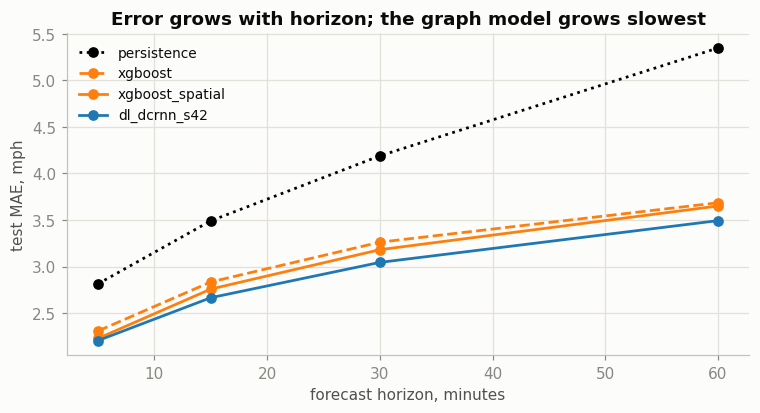

DCRNN improvement over XGBoost + neighbours (mph): {'MAE @ 5 min': 0.024, 'MAE @ 15 min': 0.093, 'MAE @ 30 min': 0.137, 'MAE @ 60 min': 0.157}


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, style in zip(keys, ["k:", "C1--", "C1-", "C0-"]):
    r = t[t.model == k]
    ax.plot(r.horizon_min, r.MAE, style, marker="o", label=k)
ax.set(xlabel="forecast horizon, minutes", ylabel="test MAE, mph", title="Error grows with horizon; the graph model grows slowest")
ax.legend(); plt.show()
gain = table.loc["xgboost_spatial"] - table.loc[RUN]
print("DCRNN improvement over XGBoost + neighbours (mph):", gain.round(3).to_dict())

## Common mistakes

* **Symmetrising the adjacency.** `A + Aᵀ` throws away direction, which is the whole point of separate `S_f` and `S_b`.
* **Normalising the wrong axis.** `D⁻¹A` must divide by the *row* sum so each row is a distribution; dividing by columns silently gives a different operator.
* **Evaluating with teacher forcing on.** At test time there is no true previous value. Validation here always runs free (`teacher_forcing=0`).
* **Blaming the GPU for slowness.** DCRNN runs 24 sequential steps × 2 layers × 3 gates of tiny matrix multiplies, so it is limited by kernel launches, not arithmetic. Pre-computing the diffusion powers and doing one big multiply (`diffusion_powers`) was a 30 % speed-up.

## Check yourself

1. Why does the forward matrix carry information from **upstream** sensors, given it is built from `D_out⁻¹ A`?
2. With K = 2 and 2 layers, what is the furthest a sensor's input can travel inside one time step?
3. DCRNN has 380 k parameters, ST-GAT (width 128) 328 k. Why is DCRNN still about 3× slower per epoch?
4. What would happen to the 60-minute forecast if the decoder were trained with teacher forcing always at 1?